<a href="https://colab.research.google.com/github/AlbertoOliveros777/Proyecto-Programacion/blob/main/Proyecto_de_Programacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
#Proyecto de Programacion (Oliveros, Gonzalez, Vargas)
carros = [
    {"modelo": "Ford Mustang",        "anio": 1967, "estado": "excelente", "precio": 120000000},
    {"modelo": "Chevrolet Camaro",    "anio": 1969, "estado": "bueno",     "precio": 95000000},
    {"modelo": "VW Escarabajo",       "anio": 1972, "estado": "regular",   "precio": 22000000},
    {"modelo": "Mercedes 280SL",      "anio": 1971, "estado": "excelente", "precio": 180000000},
    {"modelo": "Renault 4",           "anio": 1985, "estado": "bueno",     "precio": 14000000},
    {"modelo": "Jeep Willys",         "anio": 1955, "estado": "regular",   "precio": 40000000},
    {"modelo": "Porsche 911",         "anio": 1978, "estado": "bueno",     "precio": 150000000},
    {"modelo": "Mazda MX-5",          "anio": 2005, "estado": "excelente", "precio": 35000000},
    {"modelo": "Toyota Land Cruiser", "anio": 1988, "estado": "bueno",     "precio": 60000000},
    {"modelo": "Chevrolet C10",       "anio": 1979, "estado": "regular",   "precio": 45000000},
]

def clasificar(anio):
    antiguedad = 2026 - anio
    if antiguedad >= 50:
        return "coleccion"
    elif antiguedad >= 30:
        return "clasico"
    else:
        return "usado"
compradores = [
    {"nombre": "Carlos", "presupuesto": 100000000, "epoca_desde": 1960, "epoca_hasta": 1975, "estado_min": "bueno"},
    {"nombre": "Ana",    "presupuesto": 40000000,  "epoca_desde": 1980, "epoca_hasta": 2010, "estado_min": "bueno"},
    {"nombre": "Diego",  "presupuesto": 20000000,  "epoca_desde": 1980, "epoca_hasta": 2010, "estado_min": "regular"},
    {"nombre": "Sofia",  "presupuesto": 110000000, "epoca_desde": 1960, "epoca_hasta": 1972, "estado_min": "bueno"},
    {"nombre": "Mateo",  "presupuesto": 160000000, "epoca_desde": 1970, "epoca_hasta": 1985, "estado_min": "bueno"},
    {"nombre": "Laura",  "presupuesto": 50000000,  "epoca_desde": 1985, "epoca_hasta": 2005, "estado_min": "regular"},
    {"nombre": "Julian", "presupuesto": 170000000, "epoca_desde": 1970, "epoca_hasta": 1974, "estado_min": "excelente"},
]

ORDEN_ESTADO = {"regular": 1, "bueno": 2, "excelente": 3}

def le_sirve(carro, comprador, flexible=False):
    margen = 0.10 if flexible else 0
    holgura = 5 if flexible else 0
    if carro["precio"] > comprador["presupuesto"] * (1 + margen):
        return False
    if carro["anio"] < comprador["epoca_desde"] - holgura or carro["anio"] > comprador["epoca_hasta"] + holgura:
        return False
    if ORDEN_ESTADO[carro["estado"]] < ORDEN_ESTADO[comprador["estado_min"]]:
        return False
    return True

TASAS = {"coleccion": 0.05, "clasico": 0.04, "usado": 0.03}

def comision(carro, tasas):
    return carro["precio"] * tasas[clasificar(carro["anio"])]

def emparejar(carros, compradores, tasas, flexible=False, mostrar=False):
    ventas = []
    for comprador in compradores:
        matches = []
        for carro in carros:
            if le_sirve(carro, comprador, flexible):
                matches.append(carro)
        if len(matches) > 0:
            vendido = matches[0]
            for carro in matches:                        # elige el carro más valioso que puede pagar
                if carro["precio"] > vendido["precio"]:
                    vendido = carro
            cat = clasificar(vendido["anio"])
            com = comision(vendido, tasas)
            ventas.append({"comprador": comprador["nombre"], "carro": vendido["modelo"],
                           "categoria": cat, "comision": com})
            if mostrar:
                print(comprador["nombre"], "compra", vendido["modelo"], "| categoría:", cat, "| comisión:", int(com))
        else:
            if mostrar:
                print(comprador["nombre"], "no encontró carro")
    return ventas


===== ESCENARIO ESTRICTO =====
Carlos compra Chevrolet Camaro | categoría: coleccion | comisión: 4750000
Ana compra Mazda MX-5 | categoría: usado | comisión: 1050000
Diego compra Renault 4 | categoría: clasico | comisión: 560000
Sofia compra Chevrolet Camaro | categoría: coleccion | comisión: 4750000
Mateo compra Porsche 911 | categoría: clasico | comisión: 6000000
Laura compra Mazda MX-5 | categoría: usado | comisión: 1050000
Julian no encontró carro

===== ESCENARIO FLEXIBLE =====
Carlos compra Chevrolet Camaro | categoría: coleccion | comisión: 4750000
Ana compra Mazda MX-5 | categoría: usado | comisión: 1050000
Diego compra Renault 4 | categoría: clasico | comisión: 560000
Sofia compra Ford Mustang | categoría: coleccion | comisión: 6000000
Mateo compra Porsche 911 | categoría: clasico | comisión: 6000000
Laura compra Mazda MX-5 | categoría: usado | comisión: 1050000
Julian compra Mercedes 280SL | categoría: coleccion | comisión: 9000000

--- Comparación de escenarios ---
  Escenar

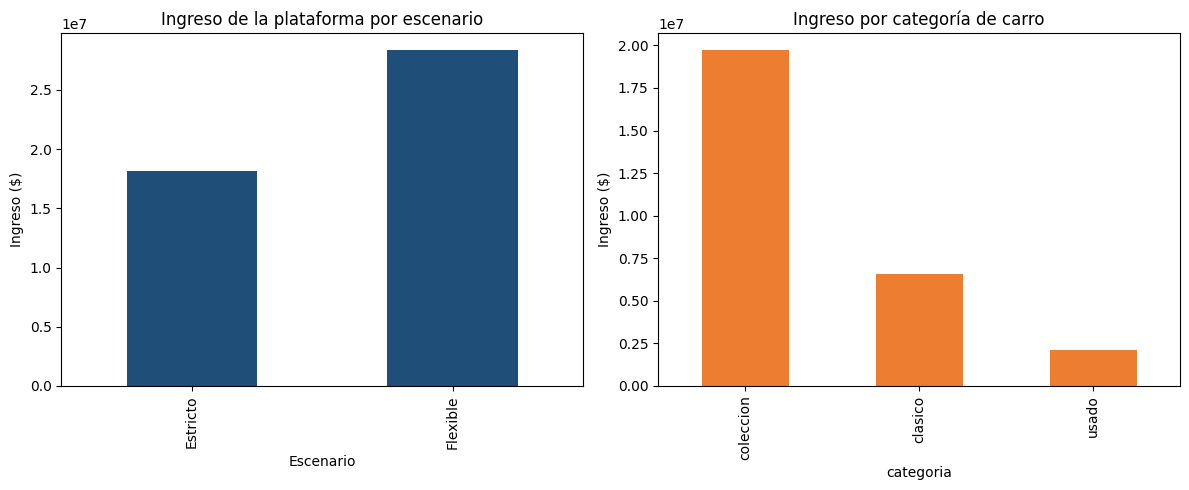

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

print("===== ESCENARIO ESTRICTO =====")
ventas_e = emparejar(carros, compradores, TASAS, flexible=False, mostrar=True)
print("\n===== ESCENARIO FLEXIBLE =====")
ventas_f = emparejar(carros, compradores, TASAS, flexible=True, mostrar=True)

ingreso_e = sum(v["comision"] for v in ventas_e)
ingreso_f = sum(v["comision"] for v in ventas_f)

comparacion = pd.DataFrame({
    "Escenario": ["Estricto", "Flexible"],
    "Ventas": [len(ventas_e), len(ventas_f)],
    "Ingreso": [ingreso_e, ingreso_f]
})
print("\n--- Comparación de escenarios ---")
print(comparacion)

# Análisis por categoría (groupby, como en el taller)
df_ventas = pd.DataFrame(ventas_f)
ingreso_cat = df_ventas.groupby("categoria")["comision"].sum().sort_values(ascending=False)
print("\n--- Ingreso por categoría (escenario flexible) ---")
print(ingreso_cat)

# Dos gráficos
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
comparacion.plot.bar(x="Escenario", y="Ingreso", ax=axs[0], legend=False, color="#1f4e79",
                     title="Ingreso de la plataforma por escenario")
axs[0].set_ylabel("Ingreso ($)")
ingreso_cat.plot.bar(ax=axs[1], color="#ed7d31", title="Ingreso por categoría de carro")
axs[1].set_ylabel("Ingreso ($)")
plt.tight_layout()
plt.show()